# Linnerud Dataset Analysis & Regression Modeling
This notebook demonstrates exploratory data analysis (EDA), multi-output linear regression modeling, evaluation, and improvement techniques (normalization, Lasso regression) on the Linnerud dataset from `scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_linnerud
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# Load the Linnerud dataset
linnerud = load_linnerud()

# Features: Chins, Situps, Jumps (Exercise data)
# Targets: Weight, Waist, Pulse (Physiological data)
# Convert to pandas DataFrames
X = pd.DataFrame(linnerud.data, columns=linnerud.feature_names)
y = pd.DataFrame(linnerud.target, columns=linnerud.target_names)

print("Features DataFrame (Exercise Data):")
display(X.head())
print("\nTargets DataFrame (Physiological Data):")
display(y.head())

Features DataFrame (Exercise Data):


,Chins,Situps,Jumps
0,5.0,162.0,60.0
1,2.0,110.0,60.0
2,12.0,101.0,101.0
3,12.0,105.0,37.0
4,13.0,155.0,58.0



Targets DataFrame (Physiological Data):


,Weight,Waist,Pulse
0,191.0,36.0,50.0
1,189.0,37.0,52.0
2,193.0,38.0,58.0
3,162.0,35.0,62.0
4,189.0,35.0,46.0


## 1. Train-Test Split
We split both features and targets into training (80%) and testing (20%) sets.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: X={X_train.shape}, y={y_train.shape}")
print(f"Testing set shape: X={X_test.shape}, y={y_test.shape}")

Training set shape: X=(16, 3), y=(16, 3)
Testing set shape: X=(4, 3), y=(4, 3)


## 2. Exploratory Data Analysis (EDA)
Let's check for missing values, calculate descriptive statistics, and plot correlations.

In [3]:
print("Missing values in Features:")
print(X_train.isnull().sum())
print("\nMissing values in Targets:")
print(y_train.isnull().sum())

print("\nFeatures descriptive statistics:")
display(X_train.describe())

print("\nTargets descriptive statistics:")
display(y_train.describe())

Missing values in Features:
Chins     0
Situps    0
Jumps     0
dtype: int64

Missing values in Targets:
Weight    0
Waist     0
Pulse     0
dtype: int64

Features descriptive statistics:


,Chins,Situps,Jumps
count,16.000000,16.000000,16.000000
mean,9.937500,137.437500,67.875000
std,5.434075,63.510596,56.028415
min,1.000000,50.000000,25.000000
25%,5.500000,101.000000,38.000000
50%,12.000000,115.000000,42.500000
75%,14.250000,202.500000,80.000000
max,17.000000,251.000000,250.000000



Targets descriptive statistics:


,Weight,Waist,Pulse
count,16.000000,16.000000,16.000000
mean,177.062500,35.375000,56.625000
std,26.164782,3.442383,7.649619
min,138.000000,31.000000,46.000000
25%,160.500000,33.000000,51.500000
50%,172.500000,34.500000,56.000000
75%,190.000000,36.250000,60.500000
max,247.000000,46.000000,74.000000


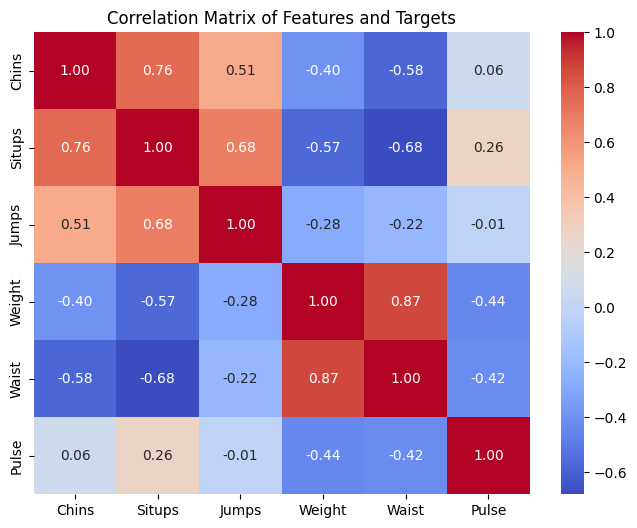

In [4]:
# Combine Features and Targets for joint analysis
combined_df = pd.concat([X_train, y_train], axis=1)

# Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(combined_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Features and Targets')
plt.show()

## 3. Build a Linear Regression Model

In [5]:
# Initialize and fit Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)
y_pred_lr_df = pd.DataFrame(y_pred_lr, columns=y.columns, index=X_test.index)

## 4. Evaluate the Model

In [6]:
def evaluate_predictions(y_true, y_pred, title):
    print(f"--- {title} ---")
    for col in y_true.columns:
        rmse = np.sqrt(mean_squared_error(y_true[col], y_pred[col]))
        r2 = r2_score(y_true[col], y_pred[col])
        print(f"Target '{col}': RMSE = {rmse:.4f}, R² = {r2:.4f}")
    print()

evaluate_predictions(y_test, y_pred_lr_df, "Simple Linear Regression Performance")

--- Simple Linear Regression Performance ---
Target 'Weight': RMSE = 25.1152, R² = -1.2433
Target 'Waist': RMSE = 2.1380, R² = -0.0755
Target 'Pulse': RMSE = 9.0617, R² = -2.7325



## 5. Visualize Predictions (Actual vs Predicted)

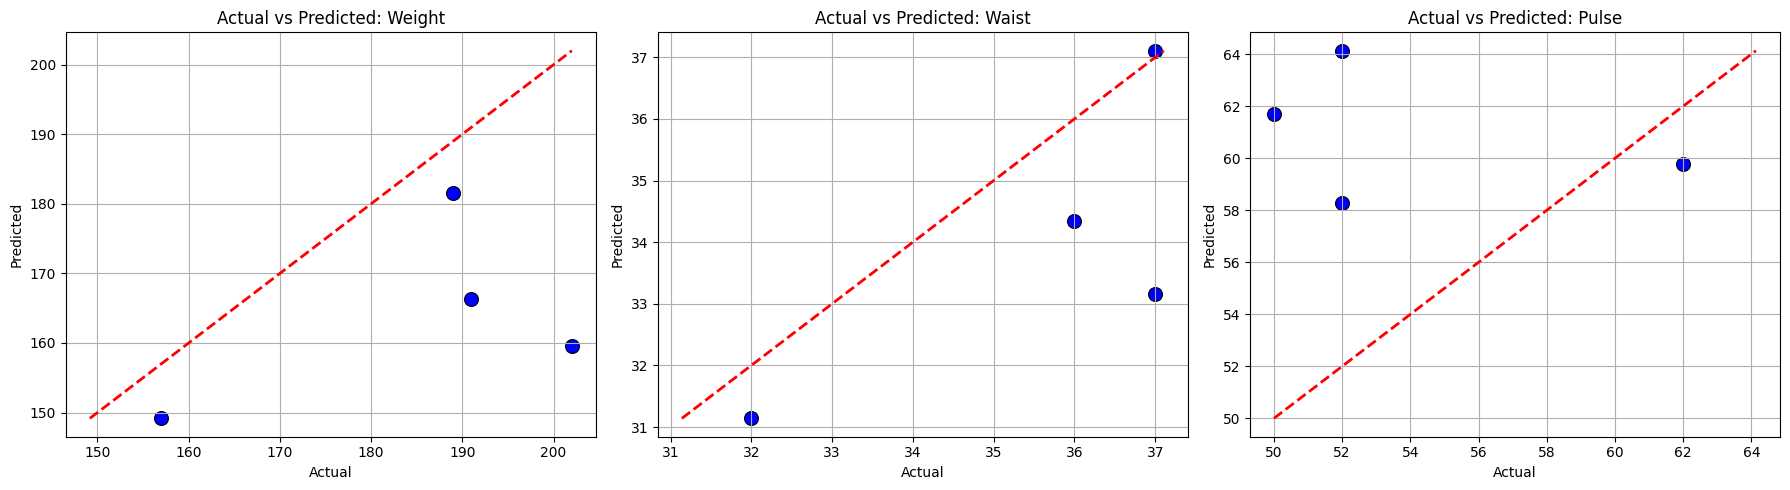

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(y.columns):
    sns.scatterplot(x=y_test[col], y=y_pred_lr_df[col], ax=axes[i], s=100, color='blue', edgecolor='k')
    # Plot ideal fit line
    min_val = min(y_test[col].min(), y_pred_lr_df[col].min())
    max_val = max(y_test[col].max(), y_pred_lr_df[col].max())
    axes[i].plot([min_val, max_val], [min_val, max_val], '--r', lw=2)
    axes[i].set_title(f'Actual vs Predicted: {col}')
    axes[i].set_xlabel('Actual')
    axes[i].set_ylabel('Predicted')
    axes[i].grid(True)
plt.tight_layout()
plt.show()

## 6. Make Predictions on New Data

In [8]:
# Pick a sample test data point
sample_input = X_test.iloc[[0]]
sample_actual = y_test.iloc[[0]]

# Predict using model
sample_pred = lr_model.predict(sample_input)
sample_pred_df = pd.DataFrame(sample_pred, columns=y.columns, index=sample_input.index)

print("New Data Input (Features):")
display(sample_input)
print("\nActual Targets:")
display(sample_actual)
print("\nPredicted Targets:")
display(sample_pred_df)

New Data Input (Features):


,Chins,Situps,Jumps
0,5.0,162.0,60.0



Actual Targets:


,Weight,Waist,Pulse
0,191.0,36.0,50.0



Predicted Targets:


,Weight,Waist,Pulse
0,166.299446,34.349313,61.692687


## 7. Model Improvement: Normalization and Alternative Models (Lasso)

In [9]:
# Normalize Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit Linear Regression on Normalized Features
lr_scaled = LinearRegression()
lr_scaled.fit(X_train_scaled, y_train)
y_pred_lr_scaled = pd.DataFrame(lr_scaled.predict(X_test_scaled), columns=y.columns, index=X_test.index)

# Fit Lasso Regression on Normalized Features
lasso = Lasso(alpha=1.0)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = pd.DataFrame(lasso.predict(X_test_scaled), columns=y.columns, index=X_test.index)

# Evaluate Models
evaluate_predictions(y_test, y_pred_lr_scaled, "Linear Regression (Normalized Features)")
evaluate_predictions(y_test, y_pred_lasso, "Lasso Regression (Normalized Features)")

--- Linear Regression (Normalized Features) ---
Target 'Weight': RMSE = 25.1152, R² = -1.2433
Target 'Waist': RMSE = 2.1380, R² = -0.0755
Target 'Pulse': RMSE = 9.0617, R² = -2.7325

--- Lasso Regression (Normalized Features) ---
Target 'Weight': RMSE = 22.7800, R² = -0.8455
Target 'Waist': RMSE = 1.8900, R² = 0.1595
Target 'Pulse': RMSE = 5.5105, R² = -0.3802

